ESPECIFICAÇÃO
  Passante 0-100 Hz (ondulação <= 1.0 dB) | rejeição >= 150 Hz (atenuação >= 40 dB) | fs = 1000 Hz

PROJETO E VERIFICAÇÃO DA ESPECIFICAÇÃO
Filtro                  ordem  coef.  ondul. (dB)  atenuação (dB)  f(-3dB) Hz  atende
--------------------------------------------------------------------------------------------------------
FIR Kaiser                 46     47        0.124           41.86       117.9    True
FIR Parks-McClellan        32     33        0.746           42.42       112.6    True
IIR Butterworth            12     25        1.000           41.03       105.4    True
IIR Chebyshev I             6     13        1.000           41.32       102.2    True
IIR Elíptico                4      9        1.000           40.00       103.6    True

FASE, ATRASO E ESTABILIDADE
Filtro                  fase linear  atraso DC (am.)  atraso DC (ms)  var. atraso passante  max|polo|  estável
--------------------------------------------------------------------------------------

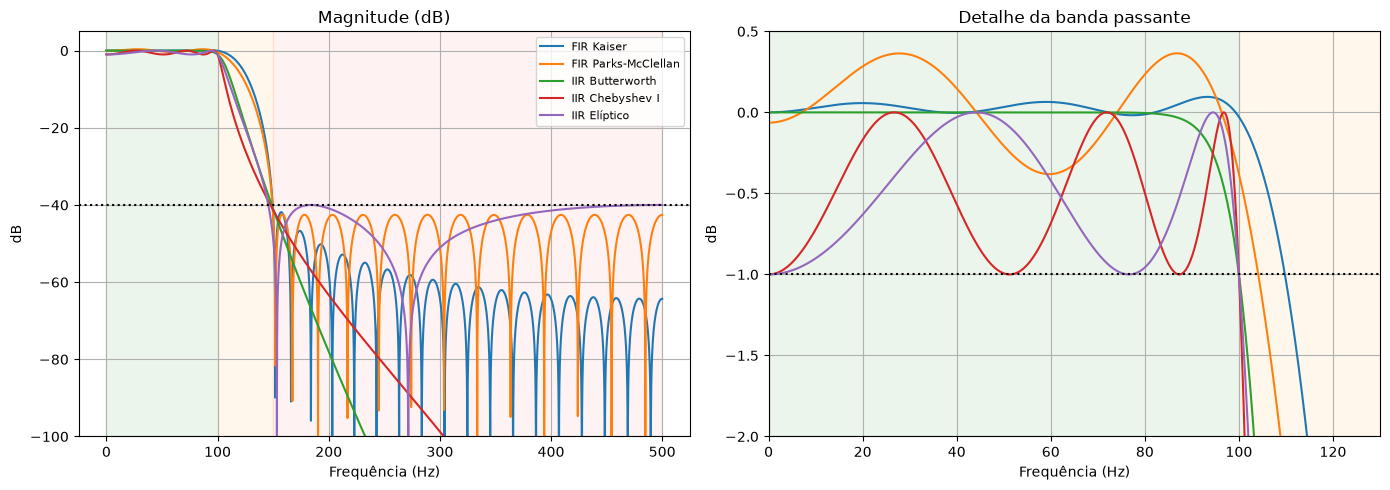

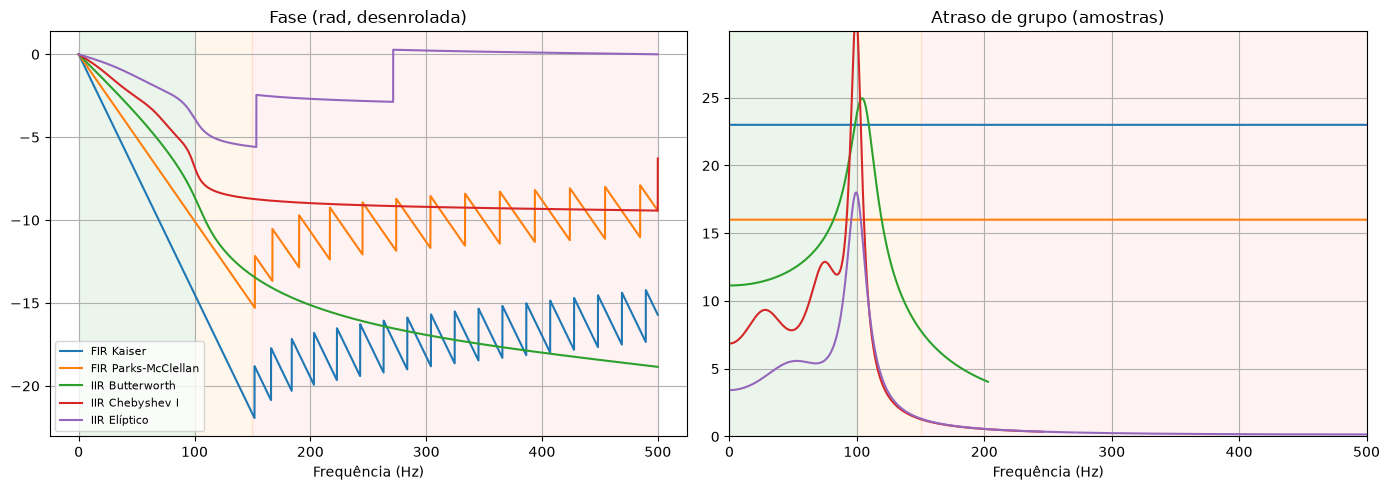

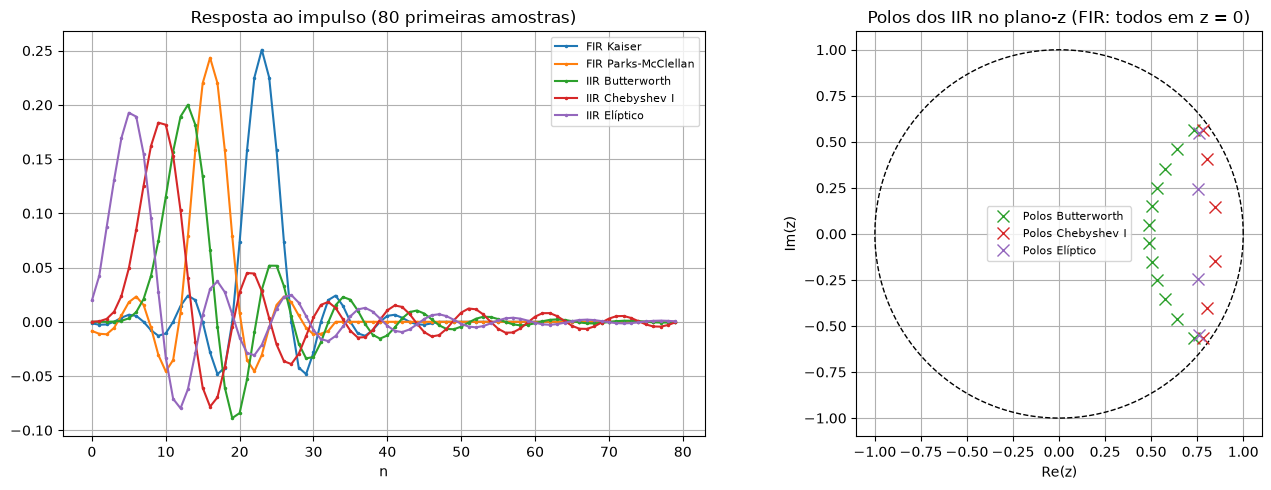

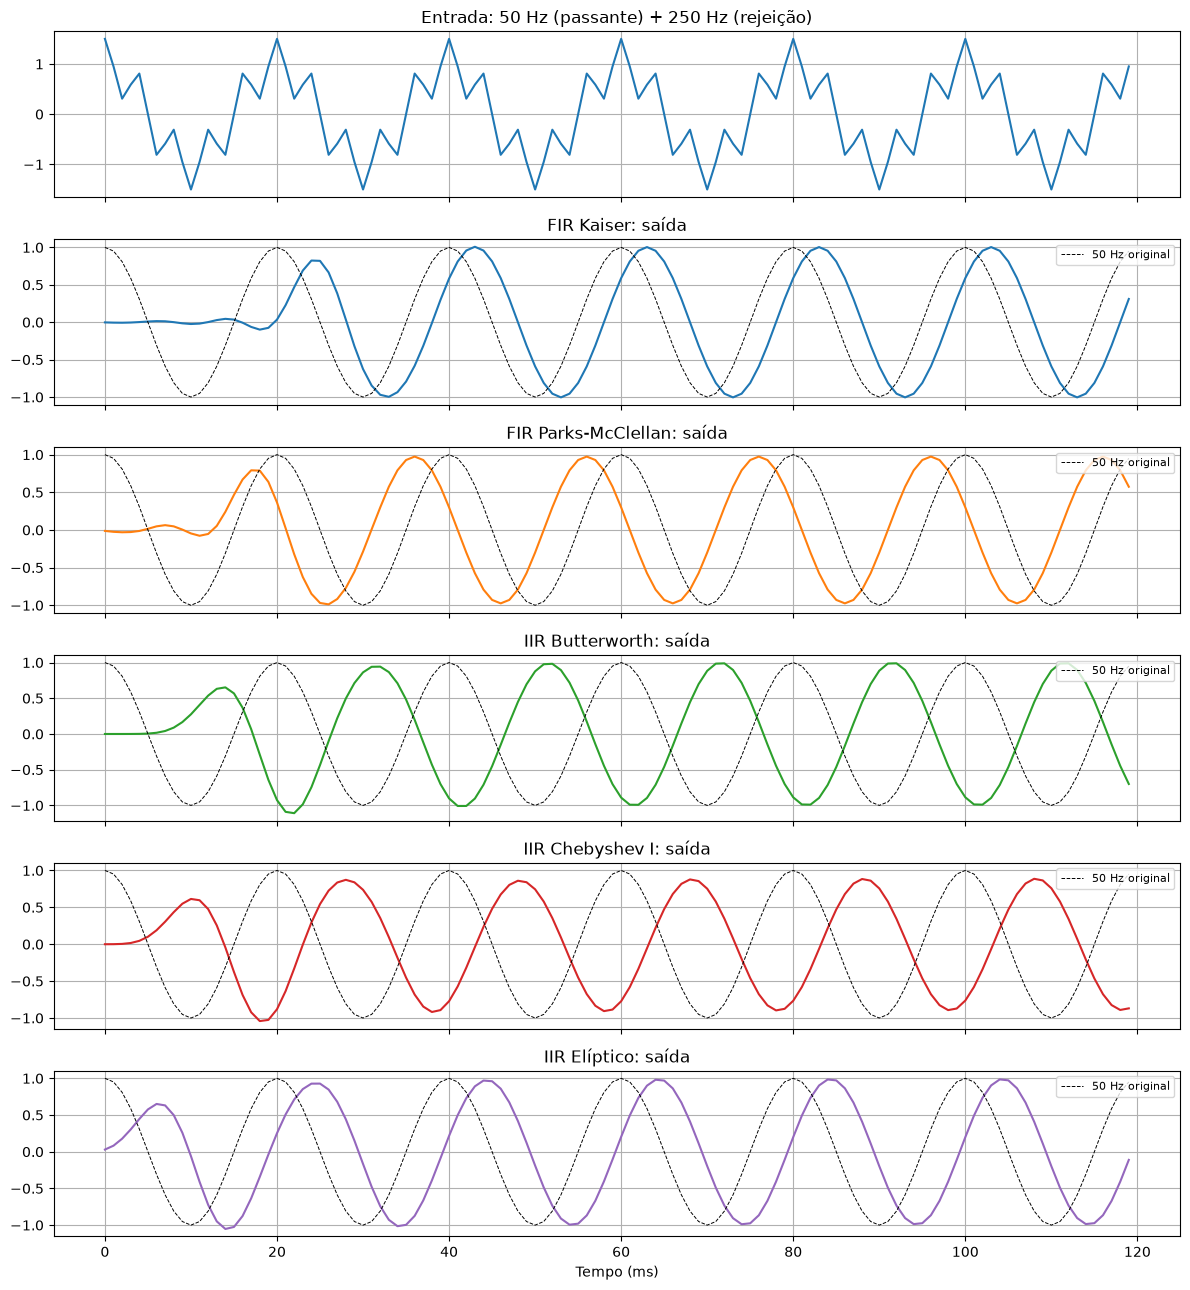

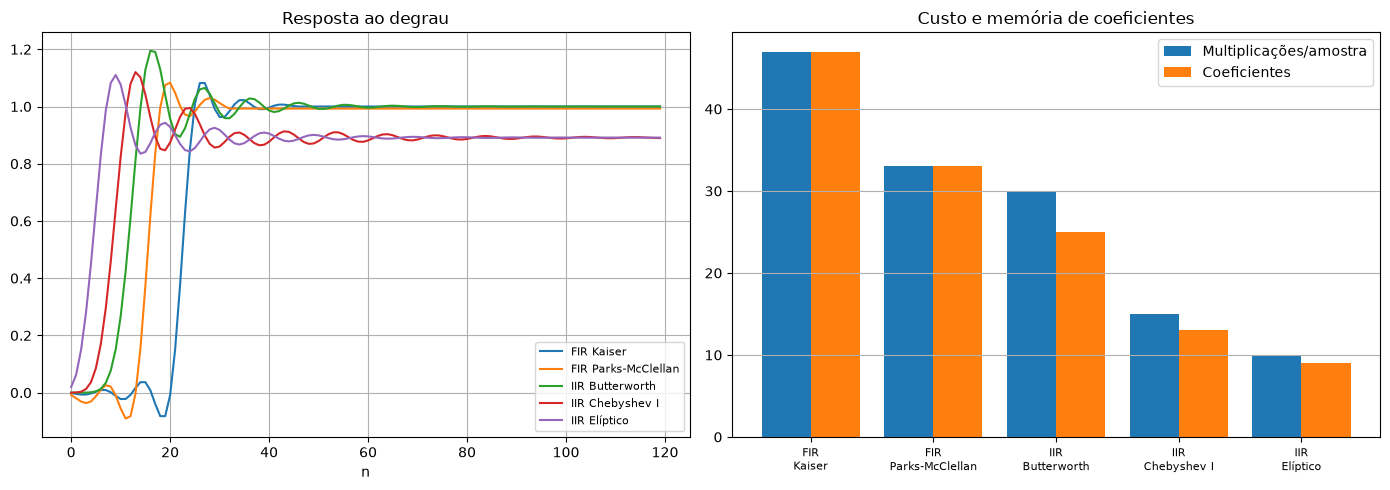


Simulação concluída!


In [1]:
"""
Roteiro de Filtros Digitais - Tópico 6: Comparação FIR x IIR

Objetivo de filtragem comum (passa-baixas), fs = 1000 Hz:
    banda passante : 0 a 100 Hz, ondulação máxima de 1 dB
    banda de rejeição : 150 Hz a 500 Hz, atenuação mínima de 40 dB
    (transição de 50 Hz)

Filtros projetados:
    FIR : janela de Kaiser (kaiserord + firwin), fase linear
    FIR : Parks-McClellan (remez), ordem mínima p/ a mesma especificação
    IIR : Butterworth, Chebyshev I e Elíptico (formato SOS)

Comparações (10.1): ordem, nº de coeficientes, magnitude, fase, estabilidade,
atraso e custo computacional aproximado. Os filtros são verificados contra
a especificação, e um teste no tempo (senoide na passante + senoide na
rejeição + degrau) mostra o comportamento de cada um.
"""

import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 1000.0
fp, fst = 100.0, 150.0           # bordas (Hz)
Rp, As = 1.0, 40.0               # ondulação (dB) e atenuação (dB)
w_hz = np.linspace(0, fs / 2, 8001)       # eixo de frequência (Hz)
w = 2 * np.pi * w_hz / fs                 # rad/amostra

# ============================================================
# 1. PROJETO DOS FILTROS
# ============================================================

# --- FIR Kaiser ---
largura = (fst - fp) / (fs / 2)             # transição normalizada (Nyquist = 1)
n_kaiser, beta = signal.kaiserord(As, largura)
if n_kaiser % 2 == 0:
    n_kaiser += 1                           # comprimento ímpar: tipo I
h_kaiser = signal.firwin(n_kaiser, (fp + fst) / 2, window=("kaiser", beta),
                         fs=fs)

# --- FIR Parks-McClellan: procura o menor comprimento que atende ---
delta_p = (10 ** (Rp / 20) - 1) / (10 ** (Rp / 20) + 1)   # erro em |H|
delta_s = 10 ** (-As / 20)
h_pm = None
for n_pm in range(11, 200, 2):
    cand = signal.remez(n_pm, [0, fp, fst, fs / 2], [1, 0],
                        weight=[1 / delta_p, 1 / delta_s], fs=fs)
    Hc = np.abs(signal.freqz(cand, 1, worN=w)[1])
    banda_p = w_hz <= fp
    banda_r = w_hz >= fst
    ok_p = 20 * np.log10(Hc[banda_p]).min() >= -Rp
    ok_r = -20 * np.log10(Hc[banda_r].max()) >= As
    if ok_p and ok_r:
        h_pm = cand
        break

# --- IIR (SOS) ---
wp, ws = fp / (fs / 2), fst / (fs / 2)
iir = {}
for nome, ordf, proj in [
    ("Butterworth", signal.buttord, signal.butter),
    ("Chebyshev I", signal.cheb1ord, signal.cheby1),
    ("Elíptico", signal.ellipord, signal.ellip),
]:
    n_ord, wn = ordf(wp, ws, Rp, As)
    if nome == "Butterworth":
        sos = proj(n_ord, wn, output="sos")
    elif nome == "Chebyshev I":
        sos = proj(n_ord, Rp, wn, output="sos")
    else:
        sos = proj(n_ord, Rp, As, wn, output="sos")
    iir[nome] = dict(ordem=n_ord, sos=sos)

# Dicionário uniforme: cada filtro com tipo, (b, a) e SOS quando IIR
filtros = {
    "FIR Kaiser": dict(tipo="FIR", b=h_kaiser, a=np.array([1.0])),
    "FIR Parks-McClellan": dict(tipo="FIR", b=h_pm, a=np.array([1.0])),
}
for nome, d in iir.items():
    b_, a_ = signal.sos2tf(d["sos"])
    filtros[f"IIR {nome}"] = dict(tipo="IIR", b=b_, a=a_, sos=d["sos"],
                                  ordem=d["ordem"])

# ============================================================
# 2. RESPOSTA EM FREQUÊNCIA E MÉTRICAS
# ============================================================

for nome, f in filtros.items():
    if f["tipo"] == "IIR":
        _, f["H"] = signal.sosfreqz(f["sos"], worN=w)
    else:
        _, f["H"] = signal.freqz(f["b"], f["a"], worN=w)
    f["mag"] = np.abs(f["H"])
    f["mag_db"] = 20 * np.log10(np.maximum(f["mag"], 1e-12))
    f["fase"] = np.unwrap(np.angle(f["H"]))
    if f["tipo"] == "FIR":
        f["ordem"] = len(f["b"]) - 1
        f["ncoef"] = len(f["b"])
        f["polos"] = np.zeros(f["ordem"])        # todos em z = 0
        sim = np.allclose(f["b"], f["b"][::-1], atol=1e-12)
        f["simetrico"] = sim
        # atraso de grupo constante (N-1)/2
        f["gd"] = np.full_like(w, (len(f["b"]) - 1) / 2)
    else:
        f["ncoef"] = len(f["b"]) + len(f["a"]) - 1       # b0..bN e a1..aN
        f["polos"] = signal.sos2zpk(f["sos"])[1]
        f["simetrico"] = False
        # atraso de grupo = -dφ/dω da fase desenrolada (estável para SOS);
        # indefinido onde |H| ~ 0 (nulos de rejeição)
        gd = -np.gradient(f["fase"], w)
        f["gd"] = np.where(f["mag"] > 1e-4, gd, np.nan)
    # métricas de magnitude
    bp = w_hz <= fp
    br = w_hz >= fst
    f["ripple_p"] = f["mag_db"][bp].max() - f["mag_db"][bp].min()
    f["atenuacao"] = -f["mag_db"][br].max()
    i3 = np.argmax(f["mag_db"] <= -3.0103)
    f["f3db"] = w_hz[i3]
    # variação do atraso de grupo na banda passante (distorção de fase)
    f["gd_var"] = np.nanmax(f["gd"][bp]) - np.nanmin(f["gd"][bp])
    f["gd0"] = f["gd"][0]
    # estabilidade
    raio = np.max(np.abs(f["polos"])) if len(f["polos"]) else 0.0
    f["raio"] = raio
    f["estavel"] = raio < 1

print("ESPECIFICAÇÃO")
print("=" * 90)
print(f"  Passante 0-{fp:.0f} Hz (ondulação <= {Rp} dB) | "
      f"rejeição >= {fst:.0f} Hz (atenuação >= {As:.0f} dB) | fs = {fs:.0f} Hz")

print("\nPROJETO E VERIFICAÇÃO DA ESPECIFICAÇÃO")
print("=" * 104)
print(f"{'Filtro':<22}{'ordem':>7}{'coef.':>7}{'ondul. (dB)':>13}"
      f"{'atenuação (dB)':>16}{'f(-3dB) Hz':>12}{'atende':>8}")
print("-" * 104)
for nome, f in filtros.items():
    atende = f["ripple_p"] <= Rp + 1e-9 and f["atenuacao"] >= As - 1e-9
    f["atende"] = atende
    print(f"{nome:<22}{f['ordem']:>7}{f['ncoef']:>7}{f['ripple_p']:>13.3f}"
          f"{f['atenuacao']:>16.2f}{f['f3db']:>12.1f}{str(atende):>8}")

# ============================================================
# 3. FASE, ATRASO E ESTABILIDADE
# ============================================================

print("\nFASE, ATRASO E ESTABILIDADE")
print("=" * 104)
print(f"{'Filtro':<22}{'fase linear':>13}{'atraso DC (am.)':>17}"
      f"{'atraso DC (ms)':>16}{'var. atraso passante':>22}"
      f"{'max|polo|':>11}{'estável':>9}")
print("-" * 104)
for nome, f in filtros.items():
    print(f"{nome:<22}{('sim (simétrico)' if f['simetrico'] else 'não'):>13}"
          f"{f['gd0']:>17.2f}{1e3 * f['gd0'] / fs:>16.2f}"
          f"{f['gd_var']:>22.3f}{f['raio']:>11.4f}{str(f['estavel']):>9}")
print("  (var. atraso passante = máx - mín do atraso de grupo em 0-100 Hz, em amostras)")

# ============================================================
# 4. CUSTO COMPUTACIONAL APROXIMADO
# ============================================================

print("\nCUSTO COMPUTACIONAL POR AMOSTRA DE SAÍDA")
print("=" * 90)
print(f"{'Filtro':<22}{'mult.':>8}{'somas':>8}{'mult. (simetria)':>18}"
      f"{'estados':>10}")
print("-" * 90)
for nome, f in filtros.items():
    if f["tipo"] == "FIR":
        N = f["ncoef"]
        f["mult"], f["soma"] = N, N - 1
        f["mult_sim"] = (N + 1) // 2 if f["simetrico"] else N
        f["estados"] = N - 1
    else:
        biq = len(f["sos"])
        f["mult"], f["soma"] = 5 * biq, 4 * biq      # forma direta I
        f["mult_sim"] = f["mult"]
        f["estados"] = 2 * biq
    print(f"{nome:<22}{f['mult']:>8}{f['soma']:>8}{f['mult_sim']:>18}"
          f"{f['estados']:>10}")
print("  (IIR em cascata de biquads, forma direta I: 5 mult. e 4 somas por seção)")

# Tempo de execução (ordem de grandeza)
x_t = np.random.default_rng(0).standard_normal(200_000)
print("\nTempo para filtrar 2e5 amostras (mediana de 7 execuções):")
for nome, f in filtros.items():
    if f["tipo"] == "FIR":
        run = lambda: signal.lfilter(f["b"], f["a"], x_t)
    else:
        run = lambda: signal.sosfilt(f["sos"], x_t)
    run()
    tempos = []
    for _ in range(7):
        t0 = time.perf_counter()
        run()
        tempos.append(1e3 * (time.perf_counter() - t0))
    f["t_ms"] = np.median(tempos)
    print(f"  {nome:<22}{f['t_ms']:>8.3f} ms")
print("  (depende da máquina e da implementação; é só ordem de grandeza)")

# ============================================================
# 5. TESTE NO TEMPO
# ============================================================

N = 2000
n = np.arange(N)
f_pass, f_rej = 50.0, 250.0
A_pass, A_rej = 1.0, 0.5
x = (A_pass * np.cos(2 * np.pi * f_pass * n / fs)
     + A_rej * np.cos(2 * np.pi * f_rej * n / fs))


def estima_tom(y, f0, n0):
    """Amplitude e atraso (amostras) da componente em f0, ajuste LS."""
    nn = np.arange(len(y))[n0:]
    w0 = 2 * np.pi * f0 / fs
    A = np.column_stack([np.cos(w0 * nn), np.sin(w0 * nn)])
    c, *_ = np.linalg.lstsq(A, y[n0:], rcond=None)
    amp = np.hypot(*c)
    fase = np.arctan2(-c[1], c[0])             # y = amp cos(w0 n + fase)
    return amp, -fase / w0


print("\nTESTE NO TEMPO: x = cos(2π·50 n/fs) + 0,5 cos(2π·250 n/fs)")
print("=" * 112)
print(f"{'Filtro':<22}{'A(50 Hz)':>10}{'A(250 Hz)':>11}{'atraso de fase medido':>23}"
      f"{'atraso de fase teórico':>24}{'atraso de grupo':>17}{'sobressinal degrau (%)':>24}")
print("-" * 112)
degrau = np.ones(400)
i50 = np.argmin(np.abs(w_hz - f_pass))
w50 = 2 * np.pi * f_pass / fs
periodo = fs / f_pass                      # 20 amostras
for nome, f in filtros.items():
    if f["tipo"] == "FIR":
        y = signal.lfilter(f["b"], f["a"], x)
        ys = signal.lfilter(f["b"], f["a"], degrau)
    else:
        y = signal.sosfilt(f["sos"], x)
        ys = signal.sosfilt(f["sos"], degrau)
    f["y"], f["ys"] = y, ys
    a50, d50 = estima_tom(y, f_pass, N // 2)
    a250, _ = estima_tom(y, f_rej, N // 2)
    # atraso de fase teórico: -φ(ω)/ω, com φ desenrolada a partir de DC.
    # O ajuste LS só enxerga o atraso módulo o período (20 amostras).
    atraso_fase = -f["fase"][i50] / w50
    d50 += periodo * np.round((atraso_fase - d50) / periodo)
    sobre = 100 * (ys.max() - ys[-1]) / ys[-1]
    f["sobre"] = sobre
    print(f"{nome:<22}{a50:>10.4f}{a250:>11.5f}{d50:>23.3f}"
          f"{atraso_fase:>24.3f}{f['gd'][i50]:>17.3f}{sobre:>24.2f}")
print("  Atrasos em amostras. O atraso de fase (-φ/ω) coincide com o de grupo "
      "só nos FIR de fase linear.")

# ============================================================
# FIGURAS
# ============================================================

cores = {"FIR Kaiser": "C0", "FIR Parks-McClellan": "C1",
         "IIR Butterworth": "C2", "IIR Chebyshev I": "C3", "IIR Elíptico": "C4"}


def faixas(ax):
    ax.axvspan(0, fp, color="green", alpha=0.08)
    ax.axvspan(fp, fst, color="orange", alpha=0.08)
    ax.axvspan(fst, fs / 2, color="red", alpha=0.05)


# Fig. 1: magnitude (dB) e detalhe da passante
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for nome, f in filtros.items():
    eixos[0].plot(w_hz, f["mag_db"], color=cores[nome], label=nome)
    eixos[1].plot(w_hz, f["mag_db"], color=cores[nome], label=nome)
faixas(eixos[0])
eixos[0].axhline(-As, color="k", linestyle=":")
eixos[0].set_ylim(-100, 5)
eixos[0].set_title("Magnitude (dB)")
faixas(eixos[1])
eixos[1].axhline(-Rp, color="k", linestyle=":")
eixos[1].set_xlim(0, 130)
eixos[1].set_ylim(-2, 0.5)
eixos[1].set_title("Detalhe da banda passante")
for ax in eixos:
    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("dB")
    ax.grid(True)
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Fig. 2: fase e atraso de grupo
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for nome, f in filtros.items():
    eixos[0].plot(w_hz, f["fase"], color=cores[nome], label=nome)
    eixos[1].plot(w_hz, f["gd"], color=cores[nome], label=nome)
eixos[0].set_title("Fase (rad, desenrolada)")
eixos[1].set_title("Atraso de grupo (amostras)")
eixos[1].set_ylim(0, 1.3 * max(f["gd0"] for f in filtros.values()))
eixos[1].set_xlim(0, fs / 2)
for ax in eixos:
    ax.set_xlabel("Frequência (Hz)")
    ax.grid(True)
    faixas(ax)
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Fig. 3: resposta ao impulso e plano-z
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
N_imp = 80
imp = np.zeros(N_imp)
imp[0] = 1
for nome, f in filtros.items():
    if f["tipo"] == "FIR":
        h = signal.lfilter(f["b"], f["a"], imp)
    else:
        h = signal.sosfilt(f["sos"], imp)
    eixos[0].plot(np.arange(N_imp), h, ".-", color=cores[nome], label=nome,
                  markersize=3)
eixos[0].set_title("Resposta ao impulso (80 primeiras amostras)")
eixos[0].set_xlabel("n")
eixos[0].legend(fontsize=8)
eixos[0].grid(True)
th = np.linspace(0, 2 * np.pi, 400)
ax = eixos[1]
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
for nome, f in filtros.items():
    if f["tipo"] == "IIR":
        ax.plot(f["polos"].real, f["polos"].imag, "x", color=cores[nome],
                markersize=9, label=f"Polos {nome[4:]}")
ax.set_aspect("equal")
ax.set_title("Polos dos IIR no plano-z (FIR: todos em z = 0)")
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.legend(fontsize=8)
ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 4: teste no tempo
t_ms = n / fs * 1e3
fig, eixos = plt.subplots(len(filtros) + 1, 1, figsize=(12, 13), sharex=True)
eixos[0].plot(t_ms[:120], x[:120])
eixos[0].set_title("Entrada: 50 Hz (passante) + 250 Hz (rejeição)")
for ax, (nome, f) in zip(eixos[1:], filtros.items()):
    ax.plot(t_ms[:120], f["y"][:120], color=cores[nome])
    ax.plot(t_ms[:120], A_pass * np.cos(2 * np.pi * f_pass * n[:120] / fs),
            "k--", linewidth=0.7, label="50 Hz original")
    ax.set_title(f"{nome}: saída")
    ax.legend(loc="upper right", fontsize=8)
for ax in eixos:
    ax.grid(True)
eixos[-1].set_xlabel("Tempo (ms)")
plt.tight_layout()
plt.show()

# Fig. 5: resposta ao degrau e custo
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for nome, f in filtros.items():
    eixos[0].plot(f["ys"][:120], color=cores[nome], label=nome)
eixos[0].set_title("Resposta ao degrau")
eixos[0].set_xlabel("n")
eixos[0].legend(fontsize=8)
eixos[0].grid(True)
nomes = list(filtros)
posic = np.arange(len(nomes))
eixos[1].bar(posic - 0.2, [filtros[k]["mult"] for k in nomes], 0.4,
             label="Multiplicações/amostra")
eixos[1].bar(posic + 0.2, [filtros[k]["ncoef"] for k in nomes], 0.4,
             label="Coeficientes")
eixos[1].set_xticks(posic)
eixos[1].set_xticklabels([k.replace(" ", "\n", 1) for k in nomes], fontsize=8)
eixos[1].set_title("Custo e memória de coeficientes")
eixos[1].legend()
eixos[1].grid(True, axis="y")
plt.tight_layout()
plt.show()

print("\nSimulação concluída!")